Khai báo thư viện

In [17]:
print("NguyenDucTinh - 6451071077")

import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import OrdinalEncoder

NguyenDucTinh - 6451071077


Nạp dữ liệu và Mã hóa (Encoding)

In [18]:
print("NguyenDucTinh - 6451071077")

data_credit = {
    'Thu nhập': ['Thấp', 'Thấp', 'Cao', 'Trung bình', 'Trung bình', 'Trung bình', 'Cao', 'Thấp', 'Thấp', 'Trung bình', 'Thấp', 'Cao', 'Cao', 'Trung bình', 'Cao'],
    'Nghề nghiệp': ['Vận tải', 'Vận tải', 'Vận tải', 'Truyền thông', 'Kinh doanh', 'Kinh doanh', 'Kinh doanh', 'Truyền thông', 'Kinh doanh', 'Truyền thông', 'Truyền thông', 'Truyền thông', 'Vận tải', 'Truyền thông', 'Kinh doanh'],
    'Tình trạng hôn nhân': ['Độc thân', 'Độc thân', 'Độc thân', 'Độc thân', 'Đã kết hôn', 'Đã kết hôn', 'Đã kết hôn', 'Độc thân', 'Đã kết hôn', 'Đã kết hôn', 'Đã kết hôn', 'Độc thân', 'Đã kết hôn', 'Độc thân', 'Độc thân'],
    'Sở hữu nhà': ['Rồi', 'Chưa', 'Rồi', 'Rồi', 'Rồi', 'Chưa', 'Chưa', 'Rồi', 'Rồi', 'Rồi', 'Chưa', 'Chưa', 'Rồi', 'Chưa', 'Rồi'],
    'Nguy cơ': ['Rủi ro cao', 'Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro cao', 'Rủi ro thấp', 'Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro cao', 'Rủi ro cao']
}

df_credit = pd.DataFrame(data_credit)
features_credit = ['Thu nhập', 'Nghề nghiệp', 'Tình trạng hôn nhân', 'Sở hữu nhà']

encoder_credit = OrdinalEncoder()
X_credit_enc = encoder_credit.fit_transform(df_credit[features_credit])
y_credit = df_credit['Nguy cơ']

display(df_credit)

NguyenDucTinh - 6451071077


,Thu nhập,Nghề nghiệp,Tình trạng hôn nhân,Sở hữu nhà,Nguy cơ
0,Thấp,Vận tải,Độc thân,Rồi,Rủi ro cao
1,Thấp,Vận tải,Độc thân,Chưa,Rủi ro cao
2,Cao,Vận tải,Độc thân,Rồi,Rủi ro thấp
3,Trung bình,Truyền thông,Độc thân,Rồi,Rủi ro thấp
4,Trung bình,Kinh doanh,Đã kết hôn,Rồi,Rủi ro thấp
5,Trung bình,Kinh doanh,Đã kết hôn,Chưa,Rủi ro cao
6,Cao,Kinh doanh,Đã kết hôn,Chưa,Rủi ro thấp
7,Thấp,Truyền thông,Độc thân,Rồi,Rủi ro cao
8,Thấp,Kinh doanh,Đã kết hôn,Rồi,Rủi ro thấp
9,Trung bình,Truyền thông,Đã kết hôn,Rồi,Rủi ro thấp


1 - Kiểm tra mâu thuẫn dữ liệu

In [19]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 1: XÁC ĐỊNH MÂU THUẪN DỮ LIỆU")
duplicates_credit = df_credit[df_credit.duplicated(subset=features_credit, keep=False)]

if len(duplicates_credit) == 0:
    print("1) KẾT LUẬN: Tập dữ liệu HOÀN TOÀN KHÔNG CÓ MÂU THUẪN (không có dòng nào trùng thuộc tính đầu vào mà khác nhãn Nguy cơ).")
else:
    print("1) Phát hiện các dòng mâu thuẫn:")
    display(duplicates_credit)

NguyenDucTinh - 6451071077
YÊU CẦU 1: XÁC ĐỊNH MÂU THUẪN DỮ LIỆU
1) KẾT LUẬN: Tập dữ liệu HOÀN TOÀN KHÔNG CÓ MÂU THUẪN (không có dòng nào trùng thuộc tính đầu vào mà khác nhãn Nguy cơ).


2 - Tính độ lợi thông tin (ID3) và vẽ cây

NguyenDucTinh - 6451071077
YÊU CẦU 2: TÍNH TOÁN CHI TIẾT ĐỘ LỢI THÔNG TIN (ID3)

Tổng số mẫu N = 15 (6 Rủi ro cao, 9 Rủi ro thấp)
-> Entropy gốc E(S) = -(6/15)*log2(6/15) - (9/15)*log2(9/15) ≈ 0.9710

--- Xét thuộc tính: 'Thu nhập' ---
  + Thu nhập = 'Thấp': 5 mẫu (3 Cao, 2 Thấp) -> E = 0.9710
  + Thu nhập = 'Cao': 5 mẫu (1 Cao, 4 Thấp) -> E = 0.7219
  + Thu nhập = 'Trung bình': 5 mẫu (2 Cao, 3 Thấp) -> E = 0.9710
  => Gain(S, Thu nhập) = 0.9710 - 0.8879 = 0.0830

--- Xét thuộc tính: 'Nghề nghiệp' ---
  + Nghề nghiệp = 'Vận tải': 4 mẫu (2 Cao, 2 Thấp) -> E = 1.0000
  + Nghề nghiệp = 'Truyền thông': 6 mẫu (2 Cao, 4 Thấp) -> E = 0.9183
  + Nghề nghiệp = 'Kinh doanh': 5 mẫu (2 Cao, 3 Thấp) -> E = 0.9710
  => Gain(S, Nghề nghiệp) = 0.9710 - 0.9576 = 0.0133

--- Xét thuộc tính: 'Tình trạng hôn nhân' ---
  + Tình trạng hôn nhân = 'Độc thân': 8 mẫu (5 Cao, 3 Thấp) -> E = 0.9544
  + Tình trạng hôn nhân = 'Đã kết hôn': 7 mẫu (1 Cao, 6 Thấp) -> E = 0.5917
  => Gain(S, Tình trạng hôn nhân) = 0.97

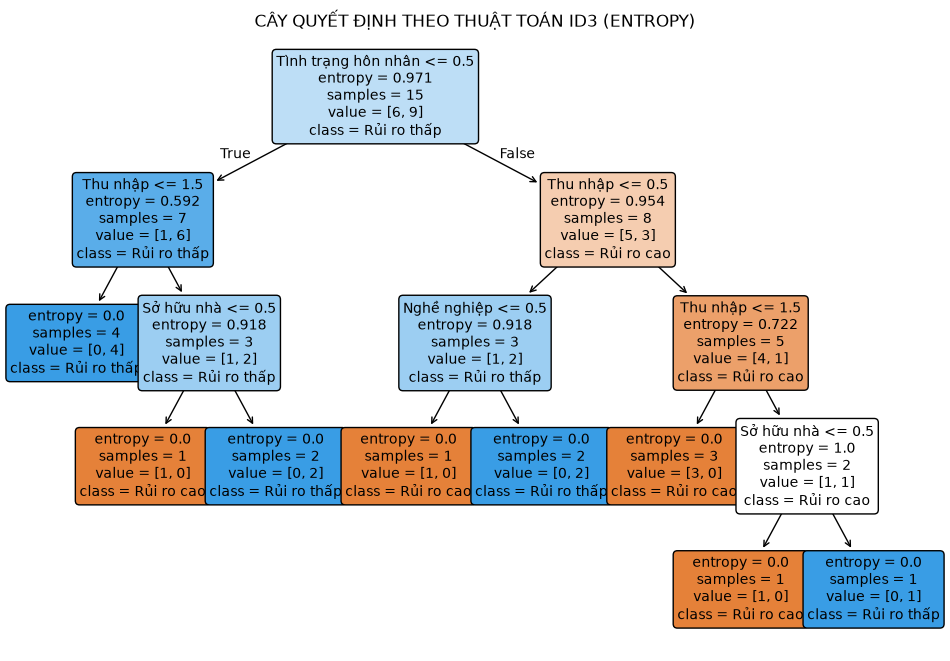

In [20]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 2: TÍNH TOÁN CHI TIẾT ĐỘ LỢI THÔNG TIN (ID3)\n")

# 1. Entropy gốc của tập S (15 mẫu: 6 Rủi ro cao, 9 Rủi ro thấp)
total_s = len(df_credit)
n_cao = sum(df_credit['Nguy cơ'] == 'Rủi ro cao')
n_thap = sum(df_credit['Nguy cơ'] == 'Rủi ro thấp')

p_cao, p_thap = n_cao / total_s, n_thap / total_s
H_S = - (p_cao * math.log2(p_cao) + p_thap * math.log2(p_thap))

print(f"Tổng số mẫu N = {total_s} (6 Rủi ro cao, 9 Rủi ro thấp)")
print(f"-> Entropy gốc E(S) = -({n_cao}/15)*log2({n_cao}/15) - ({n_thap}/15)*log2({n_thap}/15) ≈ {H_S:.4f}\n")

# Hàm tính Entropy
def calc_entropy_credit(sub_df):
    c = sum(sub_df['Nguy cơ'] == 'Rủi ro cao')
    t = sum(sub_df['Nguy cơ'] == 'Rủi ro thấp')
    tot = len(sub_df)
    if c == 0 or t == 0: return 0
    return - (c/tot * math.log2(c/tot) + t/tot * math.log2(t/tot))

# 2. Tính Gain cho từng thuộc tính ở Nút Gốc
attributes_credit = ['Thu nhập', 'Nghề nghiệp', 'Tình trạng hôn nhân', 'Sở hữu nhà']
gains_credit = {}

for attr in attributes_credit:
    entropy_attr = 0
    print(f"--- Xét thuộc tính: '{attr}' ---")
    for val in df_credit[attr].unique():
        sub = df_credit[df_credit[attr] == val]
        e = calc_entropy_credit(sub)
        weight = len(sub) / total_s
        entropy_attr += weight * e
        c_cnt = sum(sub['Nguy cơ'] == 'Rủi ro cao')
        t_cnt = sum(sub['Nguy cơ'] == 'Rủi ro thấp')
        print(f"  + {attr} = '{val}': {len(sub)} mẫu ({c_cnt} Cao, {t_cnt} Thấp) -> E = {e:.4f}")
    
    gain = H_S - entropy_attr
    gains_credit[attr] = gain
    print(f"  => Gain(S, {attr}) = {H_S:.4f} - {entropy_attr:.4f} = {gain:.4f}\n")

best_id3 = max(gains_credit, key=gains_credit.get)
print(f"===> Thuộc tính được chọn làm NÚT GỐC cho Cây ID3: '{best_id3}' (Gain cao nhất = {gains_credit[best_id3]:.4f})\n")

# --- VẼ HÌNH CÂY ID3 ---
plt.figure(figsize=(12, 8))
plot_tree(clf_id3_credit, 
          feature_names=features_credit, 
          class_names=clf_id3_credit.classes_, 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title("CÂY QUYẾT ĐỊNH THEO THUẬT TOÁN ID3 (ENTROPY)")
plt.show()


    

3 - Tính chỉ số Gini (CART) và vẽ cây

NguyenDucTinh - 6451071077
YÊU CẦU 3: TÍNH TOÁN CHI TIẾT CHỈ SỐ GINI (CART)

-> Gini gốc Gini(S) = 1 - (6/15)^2 - (9/15)^2 ≈ 0.480

--- Xét thuộc tính: 'Thu nhập' ---
  + Thu nhập = 'Thấp': 5 mẫu (3 Cao, 2 Thấp) -> Gini = 0.480
  + Thu nhập = 'Cao': 5 mẫu (1 Cao, 4 Thấp) -> Gini = 0.320
  + Thu nhập = 'Trung bình': 5 mẫu (2 Cao, 3 Thấp) -> Gini = 0.480
  => Gini_Thu nhập(S) ≈ 0.427

--- Xét thuộc tính: 'Nghề nghiệp' ---
  + Nghề nghiệp = 'Vận tải': 4 mẫu (2 Cao, 2 Thấp) -> Gini = 0.500
  + Nghề nghiệp = 'Truyền thông': 6 mẫu (2 Cao, 4 Thấp) -> Gini = 0.444
  + Nghề nghiệp = 'Kinh doanh': 5 mẫu (2 Cao, 3 Thấp) -> Gini = 0.480
  => Gini_Nghề nghiệp(S) ≈ 0.471

--- Xét thuộc tính: 'Tình trạng hôn nhân' ---
  + Tình trạng hôn nhân = 'Độc thân': 8 mẫu (5 Cao, 3 Thấp) -> Gini = 0.469
  + Tình trạng hôn nhân = 'Đã kết hôn': 7 mẫu (1 Cao, 6 Thấp) -> Gini = 0.245
  => Gini_Tình trạng hôn nhân(S) ≈ 0.364

--- Xét thuộc tính: 'Sở hữu nhà' ---
  + Sở hữu nhà = 'Rồi': 9 mẫu (3 Cao, 6 Thấp) -> Gini 

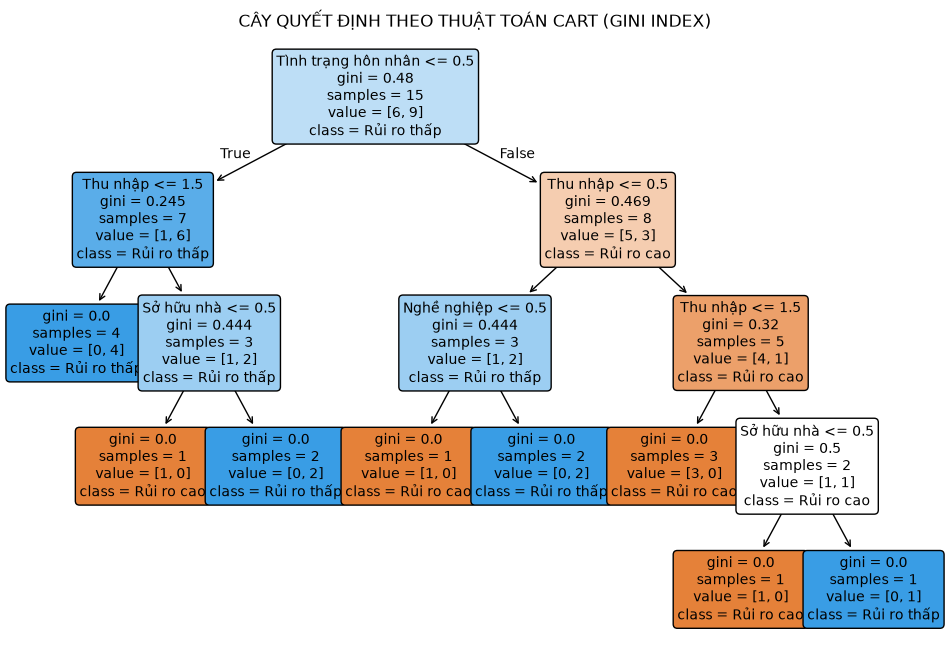

In [21]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 3: TÍNH TOÁN CHI TIẾT CHỈ SỐ GINI (CART)\n")

# 1. Gini gốc Gini(S)
gini_S = 1 - (p_cao**2 + p_thap**2)
print(f"-> Gini gốc Gini(S) = 1 - (6/15)^2 - (9/15)^2 ≈ {gini_S:.3f}\n")

def calc_gini_credit(sub_df):
    c = sum(sub_df['Nguy cơ'] == 'Rủi ro cao')
    t = sum(sub_df['Nguy cơ'] == 'Rủi ro thấp')
    tot = len(sub_df)
    if tot == 0: return 0
    return 1 - ((c/tot)**2 + (t/tot)**2)

# 2. Tính Gini Index cho từng thuộc tính ở nút gốc
ginis_credit = {}

for attr in attributes_credit:
    gini_attr = 0
    print(f"--- Xét thuộc tính: '{attr}' ---")
    for val in df_credit[attr].unique():
        sub = df_credit[df_credit[attr] == val]
        g = calc_gini_credit(sub)
        weight = len(sub) / total_s
        gini_attr += weight * g
        c_cnt = sum(sub['Nguy cơ'] == 'Rủi ro cao')
        t_cnt = sum(sub['Nguy cơ'] == 'Rủi ro thấp')
        print(f"  + {attr} = '{val}': {len(sub)} mẫu ({c_cnt} Cao, {t_cnt} Thấp) -> Gini = {g:.3f}")
    
    ginis_credit[attr] = gini_attr
    print(f"  => Gini_{attr}(S) ≈ {gini_attr:.3f}\n")

best_cart = min(ginis_credit, key=ginis_credit.get)
print(f"===> Thuộc tính phân tách tốt nhất cho Cây CART: '{best_cart}' (Gini nhỏ nhất = {ginis_credit[best_cart]:.3f})\n")

# --- 3. KHỞI TẠO VÀ HUẤN LUYỆN CÂY CART TRƯỚC KHI VẼ ---
clf_cart_credit = DecisionTreeClassifier(criterion='gini', random_state=42)
clf_cart_credit.fit(X_credit_enc, y_credit)

# --- 4. VẼ HÌNH CÂY CART ---
plt.figure(figsize=(12, 8))
plot_tree(clf_cart_credit, 
          feature_names=features_credit, 
          class_names=clf_cart_credit.classes_, 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title("CÂY QUYẾT ĐỊNH THEO THUẬT TOÁN CART (GINI INDEX)")
plt.show()

4 - Tiên đoán Nguy cơ bằng Cây quyết định (CART)

In [22]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 4: TIÊN ĐOÁN BẰNG CÂY QUYẾT ĐỊNH")
test_req4 = pd.DataFrame({
    'Thu nhập': ['Trung bình', 'Cao', 'Thấp'],
    'Nghề nghiệp': ['Vận tải', 'Truyền thông', 'Vận tải'],
    'Tình trạng hôn nhân': ['Độc thân', 'Độc thân', 'Đã kết hôn'],
    'Sở hữu nhà': ['Rồi', 'Rồi', 'Rồi']
})

X_test_req4 = encoder_credit.transform(test_req4)
y_pred_tree_c = clf_cart_credit.predict(X_test_req4)

for i, pred in enumerate(y_pred_tree_c):
    print(f"Hồ sơ {i+1}: {pred}")

NguyenDucTinh - 6451071077
YÊU CẦU 4: TIÊN ĐOÁN BẰNG CÂY QUYẾT ĐỊNH
Hồ sơ 1: Rủi ro thấp
Hồ sơ 2: Rủi ro thấp
Hồ sơ 3: Rủi ro thấp


5 - Lập ma trận nhầm lẫn, Precision, Recall cho Cây quyết định

In [23]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 5: ĐÁNH GIÁ MÔ HÌNH CÂY QUYẾT ĐỊNH")
y_true_req5 = ['Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp']
labels_credit = ['Rủi ro thấp', 'Rủi ro cao']

cm_tree_c = confusion_matrix(y_true_req5, y_pred_tree_c, labels=labels_credit)
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(pd.DataFrame(cm_tree_c, index=['Thực tế Rủi ro thấp', 'Thực tế Rủi ro cao'], columns=['Dự đoán Rủi ro thấp', 'Dự đoán Rủi ro cao']))

print("\nBáo cáo chi tiết (Precision, Recall):")
print(classification_report(y_true_req5, y_pred_tree_c, labels=labels_credit, zero_division=0))

NguyenDucTinh - 6451071077
YÊU CẦU 5: ĐÁNH GIÁ MÔ HÌNH CÂY QUYẾT ĐỊNH
Ma trận nhầm lẫn (Confusion Matrix):
                     Dự đoán Rủi ro thấp  Dự đoán Rủi ro cao
Thực tế Rủi ro thấp                    2                   0
Thực tế Rủi ro cao                     1                   0

Báo cáo chi tiết (Precision, Recall):
              precision    recall  f1-score   support

 Rủi ro thấp       0.67      1.00      0.80         2
  Rủi ro cao       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



6 - Xác suất không điều kiện của 'Truyền thông'

In [24]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 6: XÁC SUẤT KHÔNG ĐIỀU KIỆN")
n_truyen_thong = sum(df_credit['Nghề nghiệp'] == 'Truyền thông')
p_truyen_thong = n_truyen_thong / total_s
print(f"p(Nghề nghiệp = Truyền thông) = {n_truyen_thong}/{total_s} = {p_truyen_thong:.1f}")

NguyenDucTinh - 6451071077
YÊU CẦU 6: XÁC SUẤT KHÔNG ĐIỀU KIỆN
p(Nghề nghiệp = Truyền thông) = 6/15 = 0.4


7 - Xác suất thu nhập 'Thấp' khi nguy cơ là 'Rủi ro cao'

In [25]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 7: XÁC SUẤT CÓ ĐIỀU KIỆN")
df_cao_risk = df_credit[df_credit['Nguy cơ'] == 'Rủi ro cao']
n_thap_cao_risk = sum(df_cao_risk['Thu nhập'] == 'Thấp')
p_cond_7 = n_thap_cao_risk / len(df_cao_risk)
print(f"p(Thu nhập = Thấp | Nguy cơ = Rủi ro cao) = {n_thap_cao_risk}/{len(df_cao_risk)} = {p_cond_7:.1f}")

NguyenDucTinh - 6451071077
YÊU CẦU 7: XÁC SUẤT CÓ ĐIỀU KIỆN
p(Thu nhập = Thấp | Nguy cơ = Rủi ro cao) = 3/6 = 0.5


8 - Công thức định lý Bayes tính xác suất 'Rủi ro cao' khi đã sở hữu nhà

In [26]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 8: CÔNG THỨC ĐỊNH LÝ BAYES")
print("p(Nguy cơ = Rủi ro cao | Sở hữu nhà = Rồi)")
print("  = [ p(Sở hữu nhà = Rồi | Nguy cơ = Rủi ro cao) * p(Nguy cơ = Rủi ro cao) ] / p(Sở hữu nhà = Rồi)")

NguyenDucTinh - 6451071077
YÊU CẦU 8: CÔNG THỨC ĐỊNH LÝ BAYES
p(Nguy cơ = Rủi ro cao | Sở hữu nhà = Rồi)
  = [ p(Sở hữu nhà = Rồi | Nguy cơ = Rủi ro cao) * p(Nguy cơ = Rủi ro cao) ] / p(Sở hữu nhà = Rồi)


9 - Dự đoán bằng Naïve Bayes và làm trơn Laplace

In [27]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 9: DỰ ĐOÁN BẰNG NAÏVE BAYES (LAPLACE)")
clf_nb_credit = CategoricalNB(alpha=1.0)
clf_nb_credit.fit(X_credit_enc, y_credit)

y_pred_nb_c = clf_nb_credit.predict(X_test_req4)
for i, pred in enumerate(y_pred_nb_c):
    print(f"Hồ sơ {i+1}: Dự đoán = {pred}")

NguyenDucTinh - 6451071077
YÊU CẦU 9: DỰ ĐOÁN BẰNG NAÏVE BAYES (LAPLACE)
Hồ sơ 1: Dự đoán = Rủi ro cao
Hồ sơ 2: Dự đoán = Rủi ro thấp
Hồ sơ 3: Dự đoán = Rủi ro thấp


10 - Ma trận nhầm lẫn, Precision, Recall cho Naïve Bayes

In [28]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 10: ĐÁNH GIÁ MÔ HÌNH NAÏVE BAYES")
cm_nb_c = confusion_matrix(y_true_req5, y_pred_nb_c, labels=labels_credit)
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(pd.DataFrame(cm_nb_c, index=['Thực tế Rủi ro thấp', 'Thực tế Rủi ro cao'], columns=['Dự đoán Rủi ro thấp', 'Dự đoán Rủi ro cao']))

precision_nb = cm_nb_c[0,0] / (cm_nb_c[0,0] + cm_nb_c[1,0])
recall_nb = cm_nb_c[0,0] / (cm_nb_c[0,0] + cm_nb_c[0,1])

print(f"\nPrecision (Độ chính xác) = {precision_nb:.2f} ({precision_nb*100:.0f}%)")
print(f"Recall (Độ phủ)         = {recall_nb:.2f} ({recall_nb*100:.0f}%)")

NguyenDucTinh - 6451071077
YÊU CẦU 10: ĐÁNH GIÁ MÔ HÌNH NAÏVE BAYES
Ma trận nhầm lẫn (Confusion Matrix):
                     Dự đoán Rủi ro thấp  Dự đoán Rủi ro cao
Thực tế Rủi ro thấp                    2                   0
Thực tế Rủi ro cao                     0                   1

Precision (Độ chính xác) = 1.00 (100%)
Recall (Độ phủ)         = 1.00 (100%)


11 - So sánh kết quả từ Cây quyết định và Naïve Bayes

In [32]:
print("NguyenDucTinh - 6451071077")

print("YÊU CẦU 11: SO SÁNH KẾT QUẢ HAI MÔ HÌNH")
acc_tree_c = np.mean(y_pred_tree_c == y_true_req5)
acc_nb_c = np.mean(y_pred_nb_c == y_true_req5)

print(f"- Độ chính xác Cây quyết định (CART): {acc_tree_c*100:.1f}%")
print(f"- Độ chính xác Naïve Bayes (Laplace): {acc_nb_c*100:.1f}%")
print("11) Nhận xét: Mô hình Naïve Bayes đạt độ chính xác cao hơn mô hình cây quyết định trên tập dữ liệu kiểm thử này do tính toán xác suất \n toàn cục kết hợp kỹ thuật làm trơn Laplace giúp giảm thiểu hiện tượng overfitting trên tập huấn luyện nhỏ.")

NguyenDucTinh - 6451071077
YÊU CẦU 11: SO SÁNH KẾT QUẢ HAI MÔ HÌNH
- Độ chính xác Cây quyết định (CART): 66.7%
- Độ chính xác Naïve Bayes (Laplace): 100.0%
11) Nhận xét: Mô hình Naïve Bayes đạt độ chính xác cao hơn mô hình cây quyết định trên tập dữ liệu kiểm thử này do tính toán xác suất 
 toàn cục kết hợp kỹ thuật làm trơn Laplace giúp giảm thiểu hiện tượng overfitting trên tập huấn luyện nhỏ.
